## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

In [23]:
# Q1 Code moved to Phase 1 solution cell below.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts?
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Samuel Edwards

**Date:** 10/14/2026

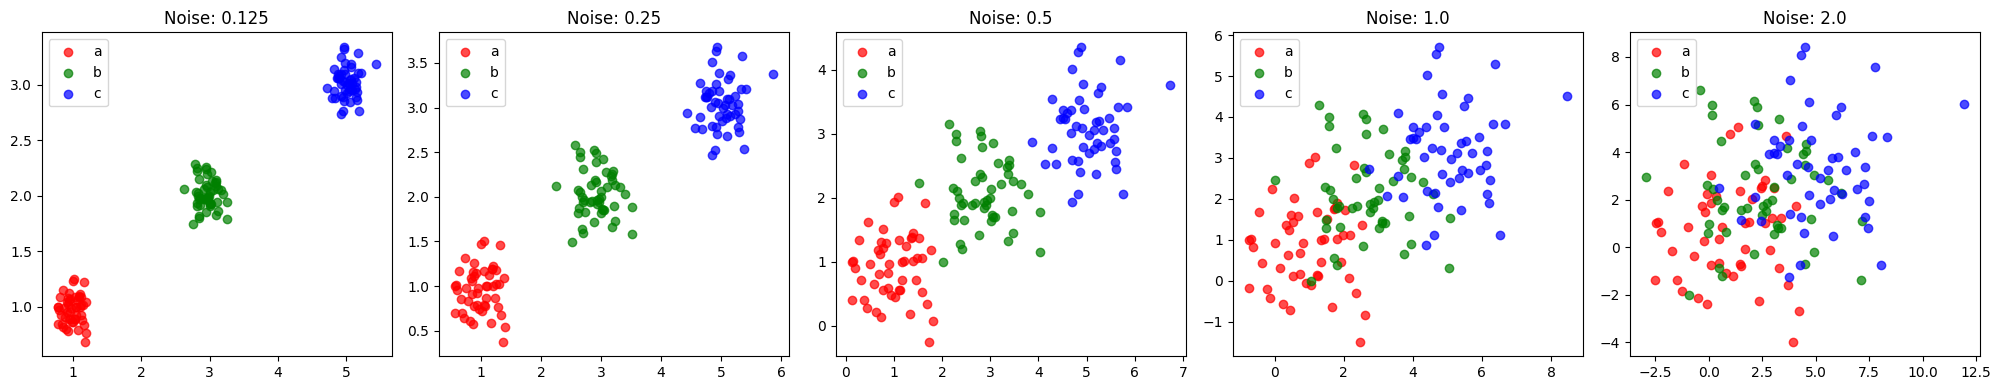

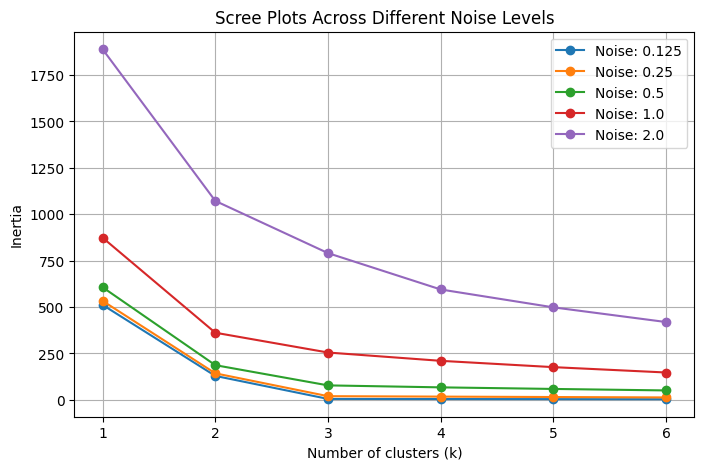

In [24]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

# Q1.1: Provided Data Generation Function
def createData(noise, N=50):
    np.random.seed(100)
    X1 = np.array([np.random.normal(1, noise, N), np.random.normal(1, noise, N)])
    X2 = np.array([np.random.normal(3, noise, N), np.random.normal(2, noise, N)])
    X3 = np.array([np.random.normal(5, noise, N), np.random.normal(3, noise, N)])
    gdf1 = pd.DataFrame({'x1': X1[0, :], 'x2': X1[1, :], 'group': 'a'})
    gdf2 = pd.DataFrame({'x1': X2[0, :], 'x2': X2[1, :], 'group': 'b'})
    gdf3 = pd.DataFrame({'x1': X3[0, :], 'x2': X3[1, :], 'group': 'c'})
    return pd.concat([gdf1, gdf2, gdf3], axis=0)

datasets = {
    '0.125': createData(0.125),
    '0.25': createData(0.25),
    '0.5': createData(0.5),
    '1.0': createData(1.0),
    '2.0': createData(2.0)
}

# Q1.2: Scatterplots by group
# as noise increases from 0.125 to 2.0, visual distinctness degrades dramatically.
# At low noise (0.125), clusters 'a', 'b', and 'c' are perfectly isolated. At high noise (2.0),
# they completely overlap into a single indistinguishable cloud of points.
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, (noise_val, df) in zip(axes, datasets.items()):
    for group, color in zip(['a', 'b', 'c'], ['red', 'green', 'blue']):
        subset = df[df['group'] == group]
        ax.scatter(subset['x1'], subset['x2'], label=group, alpha=0.7, c=color)
    ax.set_title(f"Noise: {noise_val}")
    ax.legend()
plt.tight_layout()
plt.show()

# Q1.3: Scree plots (Inertia vs. k for each dataset)
# low noise produces a very sharp "elbow" at k=3 because any cluster split beyond that
# yields negligible reduction in within-cluster variance. High noise raises the absolute
# inertia values and flattens out the curve, making it hard to find a definitive k.
fig, ax = plt.subplots(figsize=(8, 5))
k_values = range(1, 7)

for noise_val, df in datasets.items():
    X = df[['x1', 'x2']]
    inertias = []
    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=100, n_init=10).fit(X)
        inertias.append(kmeans.inertia_)
    ax.plot(k_values, inertias, marker='o', label=f"Noise: {noise_val}")

ax.set_xlabel("Number of clusters (k)")
ax.set_ylabel("Inertia")
ax.set_title("Scree Plots Across Different Noise Levels")
ax.legend()
plt.grid(True)
plt.show()

# Q1.4: Elbow Intuition
# the "elbow" represents the point of diminishing returns. Adding more clusters up to
# the true number of sub-populations (k=3) drastically drops inertia because we group distinct
# generative centers. Adding more clusters beyond k=3 merely partitions homogeneous groups,
# resulting in minor, linear decreases in inertia.

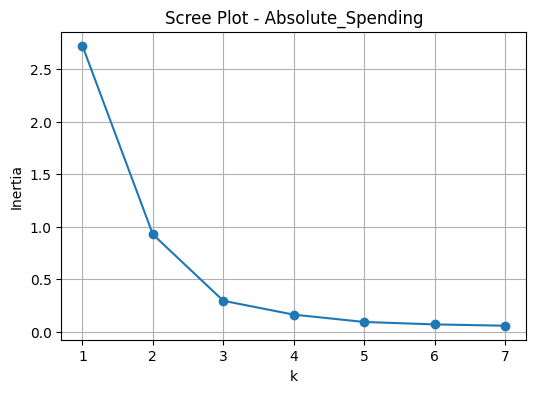

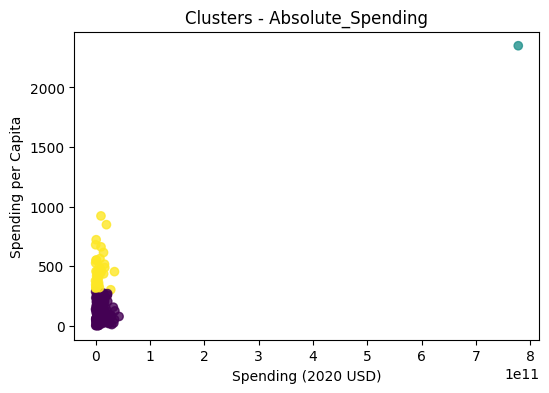


--- Describe Table: Absolute_Spending ---


Spending (2020 USD)                              \
                                        count          mean           std   
cluster_Absolute_Spending                                                   
0                                       111.0  9.975941e+09  9.511248e+09   
1                                         1.0  7.780000e+11           NaN   
2                                        36.0  7.400556e+09  8.084250e+09   

                                                                     \
                                    min           25%           50%   
cluster_Absolute_Spending                                             
0                          6.976409e+07  3.033109e+09  6.876593e+09   
1                          7.780000e+11  7.780000e+11  7.780000e+11   
2                          5.537420e+07  1.265478e+09  4.844831e+09   

                                                      Spending per Capita  \
                                    75%           max               count   
cluster_Absolute_Spending                                                   
0                          1.477349e+10  4.334146e+10               111.0   
1                          7.780000e+11  7.780000e+11                 1.0   
2                          1.005553e+10  3.492807e+10                36.0   

                                                                              \
                                  mean         std          min          25%   
cluster_Absolute_Spending                                                      
0                           117.431776   82.437628     1.014887    47.116476   
1                          2350.000000         NaN  2350.000000  2350.000000   
2                           475.757310  147.113764   302.712438   373.975651   

                                                                  
                                   50%          75%          max  
cluster_Absolute_Spending                                         
0                            94.187358   195.186510   286.777525  
1                          2350.000000  2350.000000  2350.000000  
2                           450.015256   532.893192   922.113950

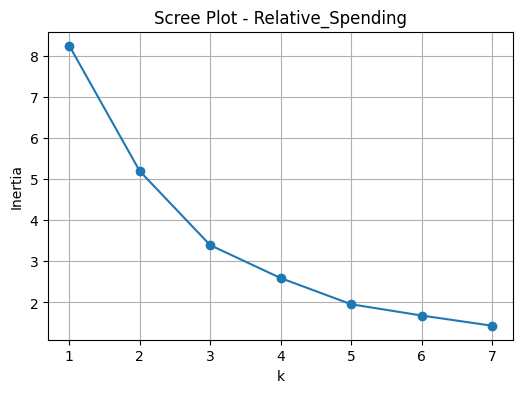

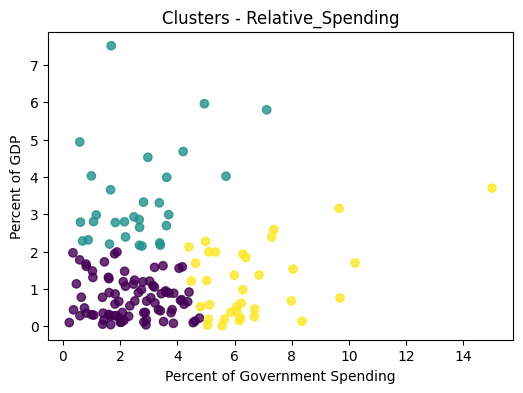


--- Describe Table: Relative_Spending ---


Percent of Government Spending                      \
                                                   count      mean       std   
cluster_Relative_Spending                                                      
0                                                   83.0  2.413304  1.195459   
1                                                   30.0  2.642196  1.538601   
2                                                   35.0  6.591065  2.079275   

                                                                              \
                                min       25%       50%       75%        max   
cluster_Relative_Spending                                                      
0                          0.221398  1.594427  2.296395  3.372628   4.771337   
1                          0.588317  1.637872  2.670281  3.399293   7.121785   
2                          4.404631  5.111288  6.167185  7.074622  15.000000   

                          Percent of GDP                                \
                                   count      mean       std       min   
cluster_Relative_Spending                                                
0                                   83.0  0.752493  0.541828  0.034219   
1                                   30.0  3.396668  1.312799  2.146173   
2                                   35.0  1.174185  0.958561  0.011626   

                                                                   
                                25%       50%       75%       max  
cluster_Relative_Spending                                          
0                          0.289882  0.670391  1.130125  1.988304  
1                          2.455164  2.892436  4.012380  7.515523  
2                          0.383503  0.976701  1.886023  3.700000

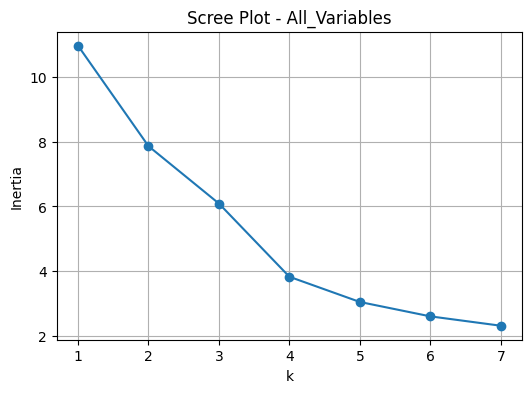

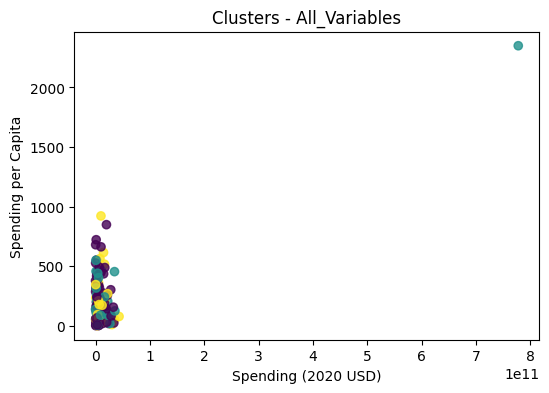


--- Describe Table: All_Variables ---


Spending (2020 USD)                              \
                                    count          mean           std   
cluster_All_Variables                                                   
0                                    82.0  8.168742e+09  8.333598e+09   
1                                    35.0  3.303446e+10  1.300002e+11   
2                                    31.0  1.050666e+10  1.036859e+10   

                                                                               \
                                min           25%           50%           75%   
cluster_All_Variables                                                           
0                      5.537420e+07  1.903907e+09  4.541259e+09  1.291529e+10   
1                      6.976409e+07  3.438667e+09  9.110544e+09  1.561281e+10   
2                      3.758448e+08  3.754716e+09  6.876593e+09  1.441320e+10   

                                    Spending per Capita              ...  \
                                max               count        mean  ...   
cluster_All_Variables                                                ...   
0                      3.370630e+10                82.0  209.655854  ...   
1                      7.780000e+11                35.0  240.819509  ...   
2                      4.334146e+10                31.0  222.313787  ...   

                      Percent of Government Spending             \
                                                 75%        max   
cluster_All_Variables                                             
0                                           3.308337   4.616023   
1                                           7.074622  15.000000   
2                                           3.510575   7.121785   

                      Percent of GDP                                          \
                               count      mean       std       min       25%   
cluster_All_Variables                                                          
0                               82.0  0.759035  0.541853  0.034219  0.298366   
1                               35.0  1.119642  0.957179  0.011626  0.313581   
2                               31.0  3.355647  1.310785  2.125000  2.351492   

                                                     
                            50%       75%       max  
cluster_All_Variables                                
0                      0.673494  1.131952  1.988304  
1                      0.752346  1.766217  3.700000  
2                      2.855213  4.004997  7.515523  

[3 rows x 32 columns]

           Country  cluster_Absolute_Spending  cluster_Relative_Spending  \
147  United States                          1                          2   

     cluster_All_Variables  
147                      1  


In [25]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
import os

# Q2.1: Load, Clean, and Check for Further Cleaning
# no further cleaning is strictly required after filtering and dropping NaNs,
# though feature scaling is necessary before distance-based clustering.
filepath = "SIPRI Military Expenditure Database.csv"
if not os.path.exists(filepath):
    filepath = "data/SIPRI Military Expenditure Database.csv"



# Helper function to run pipeline: Normalize -> Scree Plot -> KMeans -> Scatter -> Describe
def analyze_clustering(data, feature_cols, title_suffix):
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(data[feature_cols])

    # Scree plot to determine optimal k
    k_values = range(1, 8)
    inertias = []
    for k in k_values:
        kmeans = KMeans(n_clusters=k, random_state=100, n_init=10).fit(X_scaled)
        inertias.append(kmeans.inertia_)

    plt.figure(figsize=(6, 4))
    plt.plot(k_values, inertias, marker="o")
    plt.title(f"Scree Plot - {title_suffix}")
    plt.xlabel("k")
    plt.ylabel("Inertia")
    plt.grid(True)
    plt.show()

    # Optimal k selection
    optimal_k = 3
    kmeans = KMeans(n_clusters=optimal_k, random_state=100, n_init=10).fit(X_scaled)
    data[f"cluster_{title_suffix}"] = kmeans.labels_

    # Scatterplot of the first two features
    plt.figure(figsize=(6, 4))
    plt.scatter(
        data[feature_cols[0]],
        data[feature_cols[1]],
        c=data[f"cluster_{title_suffix}"],
        cmap="viridis",
        alpha=0.8,
    )
    plt.xlabel(feature_cols[0])
    plt.ylabel(feature_cols[1])
    plt.title(f"Clusters - {title_suffix}")
    plt.show()

    # Conditional Describe Table
    desc = data.groupby(f"cluster_{title_suffix}")[feature_cols].describe()
    print(f"\n--- Describe Table: {title_suffix} ---")
    display(desc)

    return data

# Q2.2: Spending (USD) and Spending per Capita
# highly skewed distributions. The US sits in an isolated cluster of 1 (or very few)
# due to its extreme total absolute spending compared to all other nations.
df_2020 = analyze_clustering(df_2020, cols_p2, "Absolute_Spending")

# Q2.3: Percentages
# comparing percentages focuses on domestic priorities. Countries with high
# militarization (like Middle Eastern nations) stand out here, grouping differently than in Part 2.
df_2020 = analyze_clustering(df_2020, cols_p3, "Relative_Spending")

# Q2.4: All Four Variables Combined
# combining both scales integrates raw power metrics (USD) and budget share
# priorities, creating robust, multi-dimensional profiles.
df_2020 = analyze_clustering(df_2020, all_vars, "All_Variables")

# Q2.5: Utility of k-Means Clustering
#  k-MC successfully identifies outliers (like the US) and characterizes profiles,
# distinguishing global spenders from domestically defense-focused nations.
if "Country" in df_2020.columns:
    print(df_2020[df_2020["Country"].str.contains("United States", na=False)][
        ["Country", "cluster_Absolute_Spending", "cluster_Relative_Spending", "cluster_All_Variables"]
    ])

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 70d01a184b3e3aa6e0aad221a528cf9ef97c6660
- **AI tool and model used:** GPT-6.1 sol.


### *Prompts used

1. Initial prompt (verbatim):

   > you are are my phase two ai agent, i need you to look at my current answers, do all the improvements you think need to be made, then put all the new answers in the appropriate cells in phase 2, then give me a numbered list of the summaries of each of the changes you made, in the format that the section of phase 2 requires

2. Follow-up prompts: None in this revision session.

### *AI-proposed changes


1. Make Phase 2 self-contained, reload the actual SIPRI CSV, and retain the 148 complete countries for 2020.
2. Correct spending and percentage units, validate the data, and exclude index and Year from clustering.
3. Improve Q1 with shared scatterplot axes, comparable scree curves, and ARI measurements of cluster recovery.
4. Correct the elbow explanation, including the effects of noise, absolute slope, and nonlinear inertia reductions.
5. Justify k using an explicit scree-curve criterion, silhouette scores, and comparisons of k=2,3,4.
6. Complete all three min-max clustering analyses with cluster sizes, describe tables, country memberships, and labeled plots.
7. Replace unsupported country claims with verified U.S. assignments and comparisons across the three feature sets.
8. Add reproducibility and seed checks, cross-model comparisons, and clear limitations about outliers, scaling, and missing countries.

### *Evaluation of AI suggestions


AI-prepared technical evaluation of the implemented revisions. Verification below was performed by the AI in this Colab session; the student should review these decisions before submission.

| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | The original Q2 depended on undefined variables and its saved output differed from the uploaded data. The revision reloads the real CSV: 5,882 source rows, 173 rows for 2020, 25 dropped, 148 unique complete countries. No mock fallback is used. |
| 2 | Accept | The actual U.S. row confirms the unit issue. Convert spending from millions to USD and shares to percentage points; exclude index and Year. Assertions verify finite, nonnegative, unique observations and identical min-max values before/after unit conversion. SIPRI's 2020 report supports the unit interpretation. |
| 3 | Accept | Identical axes make noise levels comparable; absolute and normalized scree curves distinguish scale from shape. At k=3, ARI against the known groups falls from 1.0000 at SD 0.125/0.25 to 0.2062 at SD 2.0. All five simulations have 150 observations. |
| 4 | Accept | Inertia is a squared-distance objective. A weaker elbow concerns the change in slope, and post-elbow reductions need not be linear. Verified against the computed inertia-drop table and plots. |
| 5 | Accept | Retain k=3 as a working choice selected by the stated chord criterion over k=1,...,8, but remove the claim of a definitive optimum. Silhouette favors k=2; the relative-spending chord gaps at k=2 and k=3 nearly tie. The solution explicitly reports k=2,3,4 alternatives. |
| 6 | Accept | All three feature sets are min-max scaled separately and analyzed. Required describe tables, means, counts, full country lists and scatterplots are produced; four-variable clusters have both absolute and relative projections. Counts sum to 148 in each fit. |
| 7 | Accept | Replace expectations and regional generalizations with actual results. The U.S. cluster sizes are 1 (absolute), 39 (relative), and 6 (all variables). Its six-country group contains Israel, Kuwait, Oman, Saudi Arabia, Singapore and the U.S. Numerical prose was checked against the final tables. |
| 8 | Accept | Use random_state=100 and n_init=50, report package versions, and check five alternative seeds. All three selected partitions have minimum seed-comparison ARI=1.0000. Cross-model ARIs are about 0.0492, 0.1343 and 0.6769. State remaining sensitivity to k, outliers, scaling, correlated variables and missing-country selection. |





### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

Versions: NumPy 2.1.3; pandas 2.2.3; scikit-learn 1.6.1


**Q1.1-2. Simulations and scatterplots**

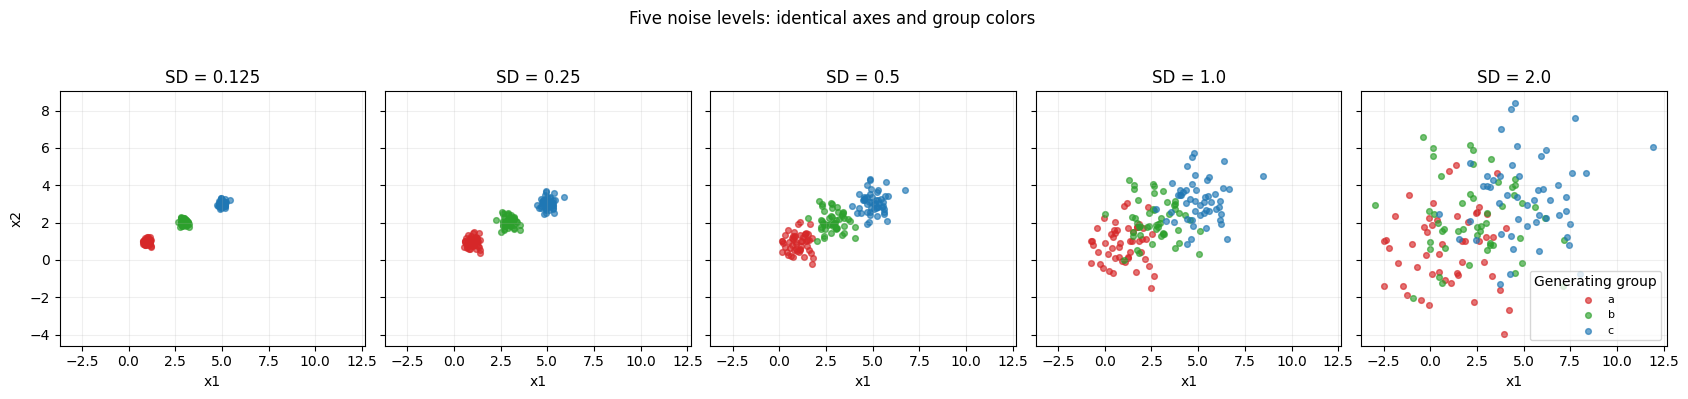

The assignment lists **five** datasets. At SD 0.125 and 0.25 the three groups are clearly separated. At 0.5 they spread toward one another; at 1.0 overlap makes boundaries ambiguous; at 2.0 overlap is substantial. The generating centers remain fixed, so increasing noise reduces separation relative to within-group variation. It does not make the underlying centers identical.

**Q1.3. Comparable scree curves and clustering quality**

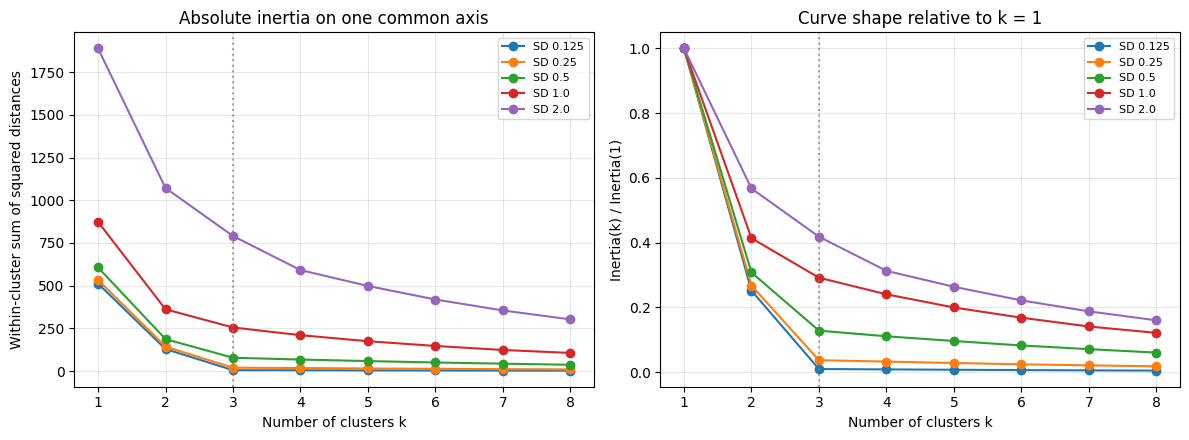

,inertia_k3,inertia_k3 / inertia_k1,drop_2_to_3,drop_3_to_4,ARI_k3_vs_generating_groups
noise_SD,,,,,
0.125,4.9132,0.0096,123.9736,0.5796,1.0000
0.250,19.6529,0.0369,123.0676,2.3183,1.0000
0.500,77.7770,0.1282,109.0042,10.5845,0.9799
1.000,254.8821,0.2917,106.7059,44.8291,0.5459
2.000,790.4791,0.4184,281.3332,199.3000,0.2062


At low noise, most improvement occurs by **k = 3**, followed by small gains: a clear elbow supports three clusters. With more noise, inertia at a fixed k generally rises, and gains after k = 3 become substantial relative to earlier gains. The elbow becomes less decisive, especially at SD 1.0 and 2.0. This means the change in slope is less distinct; it does not mean every high-noise curve has a smaller absolute slope. The normalized panel separates curve shape from vertical scale. ARI compares the fitted k = 3 partition with the known simulation labels (1 is perfect agreement); those labels are not supplied to KMeans. Overlapping groups are harder to recover even though the simulation still has three generating populations.

**Q1.4. Elbow intuition.** K-means minimizes $\sum_{j=1}^{k}\sum_{i\in C_j}\|x_i-\mu_j\|^2$. With well-separated groups, too few centroids must cover different centers, which incurs large squared distances. Reaching three centroids removes much of that between-group error. Further centroids split variation within groups and offer smaller gains. As noise increases, splitting the diffuse clouds can still reduce inertia substantially, so the location of a bend is harder to interpret. An elbow is a useful heuristic, not proof of a unique true k; post-elbow decreases need not be linear.

Q1 verification passed: five datasets, 150 observations each; all models fit.


In [26]:
# PHASE 2 - Q1. Run this cell, then the Q2 cell below.
# Independent of Phase 1 variables; the original simulation draws are preserved.
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import adjusted_rand_score, silhouette_score
from IPython.display import display, Markdown

P2_SEED = 100
P2_N_INIT = 50
print(f"Versions: NumPy {np.__version__}; pandas {pd.__version__}; scikit-learn {sklearn.__version__}")

def p2_create_data(noise, N=50):
    # RandomState preserves the assignment's np.random.seed(100) sequence
    # without changing the global random-number generator.
    rng = np.random.RandomState(P2_SEED)
    frames = []
    for label, (mu1, mu2) in zip('abc', [(1, 1), (3, 2), (5, 3)]):
        frames.append(pd.DataFrame({
            'x1': rng.normal(mu1, noise, N),
            'x2': rng.normal(mu2, noise, N),
            'group': label,
        }))
    return pd.concat(frames, ignore_index=True)

p2_datasets = {s: p2_create_data(s) for s in [0.125, 0.25, 0.5, 1.0, 2.0]}
assert all(len(d) == 150 and d['group'].nunique() == 3 for d in p2_datasets.values())

display(Markdown('**Q1.1-2. Simulations and scatterplots**'))
fig, axes = plt.subplots(1, 5, figsize=(17, 4), sharex=True, sharey=True)
for ax, (noise, data) in zip(axes, p2_datasets.items()):
    for group, color in zip('abc', ['tab:red', 'tab:green', 'tab:blue']):
        points = data.loc[data['group'].eq(group)]
        ax.scatter(points.x1, points.x2, label=group, color=color, s=17, alpha=0.65)
    ax.set(title=f'SD = {noise}', xlabel='x1')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.2)
axes[0].set_ylabel('x2')
axes[-1].legend(title='Generating group', fontsize=8)
fig.suptitle('Five noise levels: identical axes and group colors')
plt.tight_layout()
plt.show()
display(Markdown(
    'The assignment lists **five** datasets. At SD 0.125 and 0.25 the three groups '
    'are clearly separated. At 0.5 they spread toward one another; at 1.0 overlap '
    'makes boundaries ambiguous; at 2.0 overlap is substantial. The generating '
    'centers remain fixed, so increasing noise reduces separation relative to '
    'within-group variation. It does not make the underlying centers identical.'
))

display(Markdown('**Q1.3. Comparable scree curves and clustering quality**'))
p2_k_grid = list(range(1, 9))
p2_q1_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for noise, data in p2_datasets.items():
    X = data[['x1', 'x2']]
    models = {k: KMeans(n_clusters=k, random_state=P2_SEED,
                        n_init=P2_N_INIT).fit(X) for k in p2_k_grid}
    inertia = np.array([models[k].inertia_ for k in p2_k_grid])
    axes[0].plot(p2_k_grid, inertia, 'o-', label=f'SD {noise}')
    axes[1].plot(p2_k_grid, inertia / inertia[0], 'o-', label=f'SD {noise}')
    p2_q1_rows.append({
        'noise_SD': noise,
        'inertia_k3': inertia[2],
        'inertia_k3 / inertia_k1': inertia[2] / inertia[0],
        'drop_2_to_3': inertia[1] - inertia[2],
        'drop_3_to_4': inertia[2] - inertia[3],
        'ARI_k3_vs_generating_groups': adjusted_rand_score(data.group, models[3].labels_),
    })
for ax in axes:
    ax.set_xlabel('Number of clusters k')
    ax.set_xticks(p2_k_grid)
    ax.axvline(3, color='grey', linestyle=':', alpha=0.7)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set(title='Absolute inertia on one common axis', ylabel='Within-cluster sum of squared distances')
axes[1].set(title='Curve shape relative to k = 1', ylabel='Inertia(k) / Inertia(1)')
plt.tight_layout()
plt.show()
p2_q1_summary = pd.DataFrame(p2_q1_rows).set_index('noise_SD')
display(p2_q1_summary.round(4))
display(Markdown(
    'At low noise, most improvement occurs by **k = 3**, followed by small gains: '
    'a clear elbow supports three clusters. With more noise, inertia at a fixed k '
    'generally rises, and gains after k = 3 become substantial relative to earlier '
    'gains. The elbow becomes less decisive, especially at SD 1.0 and 2.0. '
    'This means the change in slope is less distinct; it does not mean every '
    'high-noise curve has a smaller absolute slope. The normalized panel separates '
    'curve shape from vertical scale. ARI compares the fitted k = 3 partition '
    'with the known simulation labels (1 is perfect agreement); those labels '
    'are not supplied to KMeans. Overlapping groups are harder to recover even '
    'though the simulation still has three generating populations.'
))
display(Markdown(
    '**Q1.4. Elbow intuition.** K-means minimizes '
    r'$\sum_{j=1}^{k}\sum_{i\in C_j}\|x_i-\mu_j\|^2$. '
    'With well-separated groups, too few centroids must cover different centers, '
    'which incurs large squared distances. Reaching three centroids removes much '
    'of that between-group error. Further centroids split variation within groups '
    'and offer smaller gains. As noise increases, splitting the diffuse clouds '
    'can still reduce inertia substantially, so the location of a bend is harder '
    'to interpret. An elbow is a useful heuristic, not proof of a unique true k; '
    'post-elbow decreases need not be linear.'
))
print('Q1 verification passed: five datasets, 150 observations each; all models fit.')


**Q2.1. Cleaning and units**

Loaded: SIPRI Military Expenditure Database.csv; source rows: 5882; 2020 rows: 173; dropped: 25; retained: 148 countries.


,Missing in 2020 before removal
Year,0
Country,0
Spending (2020 USD),23
Percent of GDP,23
Percent of Government Spending,25
Spending per Capita,24


,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
144,United States of America,7.783972e+11,2351.631858,8.197624,3.717885


Further preparation is required: exclude the exported **index** column and the constant **Year** from clustering, validate numeric types and country uniqueness, correct units, then scale the selected features. In this file, the U.S. spending entry 778397.2 represents **millions of USD**, giving **USD 778.3972 billion**; its GDP entry 0.037179 represents about **3.718%**, not 0.037179%. These unit interpretations are consistent with [SIPRI's 2020 report](https://www.sipri.org/media/press-release/2021/world-military-spending-rises-almost-2-trillion-2020). The unit check is an inference from the supplied values and that report. The retained rows are finite, nonnegative and unique by country. No additional numeric parsing is needed for this particular CSV. Removing 25 incomplete countries may introduce selection bias. Extreme observations are retained as substantive data rather than treated as errors.

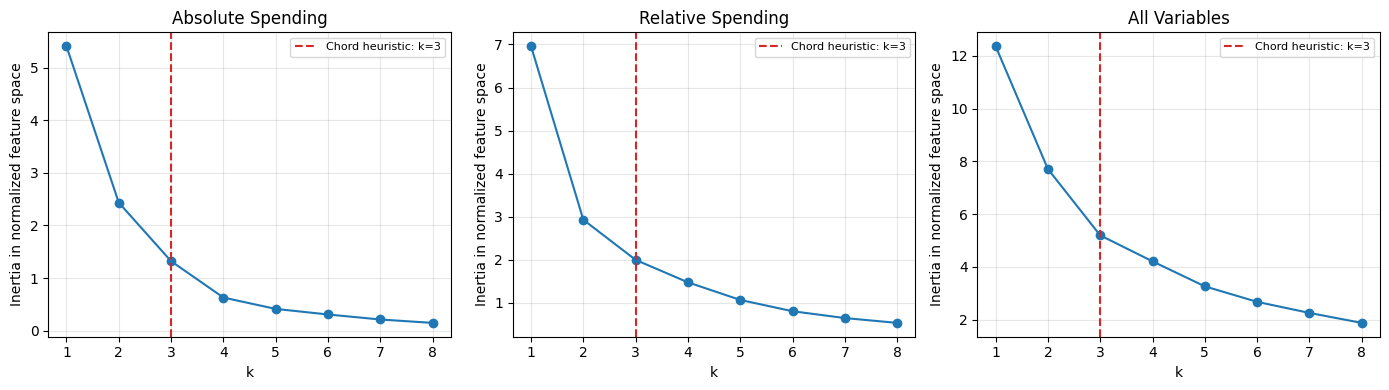

**Absolute_Spending: candidate-k evidence**

,inertia,drop_from_previous_pct,silhouette,elbow_chord_gap
k,,,,
1,5.4114,NaN,NaN,0.0000
2,2.4353,54.9975,0.7592,0.4225
3,1.3218,45.7224,0.7430,0.4911
4,0.6294,52.3821,0.7014,0.4798
5,0.4131,34.3642,0.6668,0.3780
6,0.3070,25.6983,0.6711,0.2553
7,0.2116,31.0696,0.6534,0.1306
8,0.1471,30.4839,0.6001,0.0000


**Relative_Spending: candidate-k evidence**

,inertia,drop_from_previous_pct,silhouette,elbow_chord_gap
k,,,,
1,6.9609,NaN,NaN,0.0000
2,2.9274,57.9450,0.6159,0.4846
3,1.9958,31.8244,0.5394,0.4866
4,1.4745,26.1217,0.4460,0.4249
5,1.0657,27.7233,0.4378,0.3456
6,0.8033,24.6223,0.4162,0.2436
7,0.6445,19.7670,0.3774,0.1254
8,0.5323,17.4113,0.3844,0.0000


**All_Variables: candidate-k evidence**

...

,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster_Absolute_Spending,,,,
0,5.943346e+09,122.034996,6.007354,1.764081
1,1.997599e+10,1046.433509,6.915410,3.064889
2,7.783972e+11,2351.631858,8.197624,3.717885


**Conditional describe table** (corrected USD, USD per person and percentage-point units)

cluster_Absolute_Spending             0             1             2
Spending (2020 USD) count  1.260000e+02  2.100000e+01  1.000000e+00
                    mean   5.943346e+09  1.997599e+10  7.783972e+11
                    std    2.485896e+10  2.174974e+10           NaN
                    min    8.622460e+06  4.057905e+08  7.783972e+11
                    25%    1.627617e+08  4.980428e+09  7.783972e+11
                    50%    5.807583e+08  7.269880e+09  7.783972e+11
                    75%    3.225333e+09  2.730089e+10  7.783972e+11
                    max    2.579734e+11  6.455840e+10  7.783972e+11
Spending per Capita count  1.260000e+02  2.100000e+01  1.000000e+00
                    mean   1.220350e+02  1.046434e+03  2.351632e+03
                    std    1.400412e+02  5.016318e+02           NaN
                    min    5.801292e-01  6.168544e+02  2.351632e+03
                    25%    1.850581e+01  7.376902e+02  2.351632e+03
                    50%    5.880911e+01  8.598805e+02  2.351632e+03
                    75%    1.882494e+02  1.193599e+03  2.351632e+03
                    max    5.411548e+02  2.520399e+03  2.351632e+03

**Country membership by cluster**

,Country
cluster_Absolute_Spending,
0,"Afghanistan, Albania, Algeria, Angola, Argentina, Armenia, Austria, Azerbaijan, Bangladesh, Belarus, Belgium, Belize, Benin, Bolivia, Bosnia and Herzegovina, Botswana, Brazil, Bulgaria, Burkina Faso, Burundi, Cambodia, Cameroon, Cape Verde, Central African Republic, Chad, Chile, China, Colombia, Congo, DR, Congo, Republic, Croatia, Cyprus, Czechia, Dominican Republic, Ecuador, Egypt, El Salvador, Equatorial Guinea, Estonia, Ethiopia, Fiji, Gabon, Gambia, The, Georgia, Ghana, Greece, Guatemala, Guinea, Guinea-Bissau, Guyana, Haiti, Honduras, Hungary, India, Indonesia, Iran, Iraq, Ireland, Italy, Jamaica, Japan, Jordan, Kazakhstan, Kenya, Kosovo, Kyrgyz Republic, Latvia, Lebanon, Lesotho, Liberia, Lithuania, Madagascar, Malawi, Malaysia, Mali, Malta, Mauritania, Mauritius, Mexico, Moldova, Mongolia, Montenegro, Morocco, Mozambique, Myanmar, Namibia, Nepal, Nicaragua, Niger, Nigeria, North Macedonia, Pakistan, Papua New Guinea, Paraguay, Peru, Philippines, Poland, Portugal, Romania, Russia, Rwanda, Senegal, Serbia, Seychelles, Sierra Leone, Slovakia, Slovenia, South Africa, South Sudan, Spain, Sri Lanka, Sudan, Taiwan, Tajikistan, Tanzania, Thailand, Timor Leste, Togo, Trinidad and Tobago, Tunisia, Turkey, Uganda, Ukraine, Uruguay, Zambia, Zimbabwe"
1,"Australia, Bahrain, Brunei, Canada, Denmark, Finland, France, Germany, Israel, Korea, South, Kuwait, Luxembourg, Netherlands, New Zealand, Norway, Oman, Saudi Arabia, Singapore, Sweden, Switzerland, United Kingdom"
2,United States of America


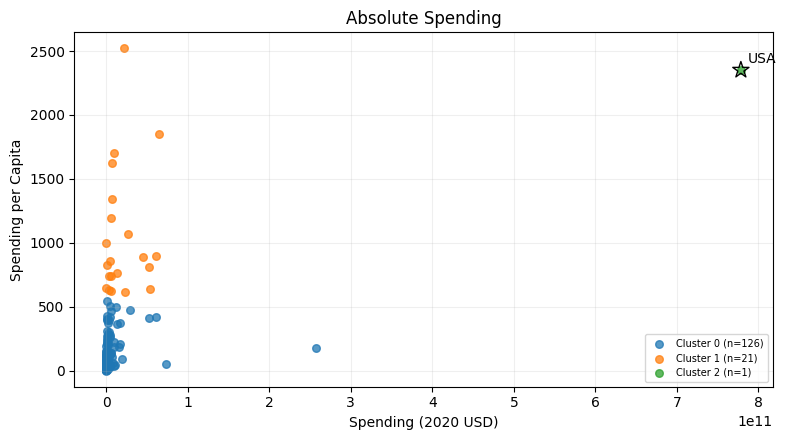

**Relative_Spending: selected k=3; cluster sizes and mean profiles**

,Countries
cluster_Relative_Spending,
0,39
1,99
2,10


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster_Relative_Spending,,,,
0,2.738715e+10,271.264618,9.868285,2.741195
1,7.611174e+09,211.624304,3.577738,1.266440
2,1.251496e+10,817.301890,17.128868,5.807064


**Conditional describe table** (corrected USD, USD per person and percentage-point units)

cluster_Relative_Spending                     0          1          2
Percent of Government Spending count  39.000000  99.000000  10.000000
                               mean    9.868285   3.577738  17.128868
                               std     2.412455   1.454858   5.872477
                               min     5.951952   0.489643   9.788241
                               25%     8.243032   2.592130  13.501039
                               50%     9.204434   3.426083  16.824799
                               75%    11.263275   4.740243  17.908082
                               max    15.791773   7.462364  30.302658
Percent of GDP                 count  39.000000  99.000000  10.000000
                               mean    2.741195   1.266440   5.807064
                               std     0.819104   0.568135   2.486692
                               min     1.131726   0.005400   1.174170
                               25%     2.125404   0.839281   4.929728
                               50%     2.778110   1.319075   5.372879
                               75%     3.246137   1.675223   6.619012
                               max     4.281029   2.813162   9.847033

**Country membership by cluster**

,Country
cluster_Relative_Spending,
0,"Bahrain, Bangladesh, Botswana, Brunei, Burkina Faso, Burundi, Cambodia, Central African Republic, Chad, Chile, Colombia, Congo, Republic, Ecuador, Equatorial Guinea, Gabon, Guinea, India, Iran, Iraq, Korea, South, Lebanon, Mali, Mauritania, Morocco, Myanmar, Namibia, Niger, Russia, Singapore, South Sudan, Sri Lanka, Sudan, Taiwan, Togo, Tunisia, Turkey, Uganda, Ukraine, United States of America"
1,"Afghanistan, Albania, Angola, Argentina, Australia, Austria, Belgium, Belize, Benin, Bolivia, Bosnia and Herzegovina, Brazil, Bulgaria, Cameroon, Canada, Cape Verde, China, Congo, DR, Croatia, Cyprus, Czechia, Denmark, Dominican Republic, Egypt, El Salvador, Estonia, Ethiopia, Fiji, Finland, France, Gambia, The, Georgia, Germany, Ghana, Greece, Guatemala, Guinea-Bissau, Guyana, Haiti, Honduras, Hungary, Indonesia, Ireland, Italy, Jamaica, Japan, Kazakhstan, Kenya, Kosovo, Kyrgyz Republic, Latvia, Lesotho, Liberia, Lithuania, Luxembourg, Madagascar, Malawi, Malaysia, Malta, Mauritius, Mexico, Moldova, Mongolia, Montenegro, Mozambique, Nepal, Netherlands, New Zealand, Nicaragua, Nigeria, North Macedonia, Norway, Papua New Guinea, Paraguay, Peru, Philippines, Poland, Portugal, Romania, Rwanda, Senegal, Serbia, Seychelles, Sierra Leone, Slovakia, Slovenia, South Africa, Spain, Sweden, Switzerland, Tajikistan, Tanzania, Thailand, Timor Leste, Trinidad and Tobago, United Kingdom, Uruguay, Zambia, Zimbabwe"
2,"Algeria, Armenia, Azerbaijan, Belarus, Israel, Jordan, Kuwait, Oman, Pakistan, Saudi Arabia"


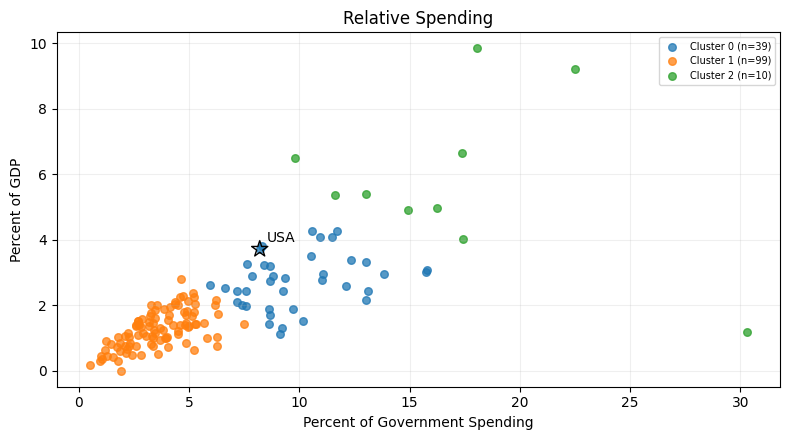

**All_Variables: selected k=3; cluster sizes and mean profiles**

,Countries
cluster_All_Variables,
0,111
1,6
2,31


,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP
cluster_All_Variables,,,,
0,7.086473e+09,196.926833,4.035002,1.341886
1,1.479646e+11,1875.150751,13.535058,6.263368
2,8.786087e+09,212.689100,12.298459,3.349201


**Conditional describe table** (corrected USD, USD per person and percentage-point units)

cluster_All_Variables                            0             1             2
Spending (2020 USD)            count  1.110000e+02  6.000000e+00  3.100000e+01
                               mean   7.086473e+09  1.479646e+11  8.786087e+09
                               std    2.647938e+10  3.096352e+11  1.790191e+10
                               min    8.622460e+06  6.095709e+09  1.623734e+08
                               25%    1.300102e+08  7.700425e+09  4.677879e+08
                               50%    5.676507e+08  1.589757e+10  1.404787e+09
                               75%    3.910107e+09  5.387294e+10  7.739166e+09
                               max    2.579734e+11  7.783972e+11  7.293706e+10
Spending per Capita            count  1.110000e+02  6.000000e+00  3.100000e+01
                               mean   1.969268e+02  1.875151e+03  2.126891e+02
                               std    2.677885e+02  4.898002e+02  2.578420e+02
                               min    5.801292e-01  1.193599e+03  1.829712e+01
                               25%    1.488055e+01  1.645302e+03  4.648592e+01
                               50%    6.708342e+01  1.780060e+03  1.354598e+02
                               75%    2.952961e+02  2.227319e+03  2.173338e+02
                               max    1.341059e+03  2.520399e+03  9.989662e+02
Percent of Government Spending count  1.110000e+02  6.000000e+00  3.100000e+01
                               mean   4.035002e+00  1.353506e+01  1.229846e+01
                               std    1.931981e+00  5.539236e+00  4.392738e+00
                               min    4.896432e-01  8.197624e+00  7.600472e+00
                               25%    2.671243e+00  1.010341e+01  9.309299e+00
                               50%    3.795233e+00  1.132706e+01  1.147762e+01
                               75%    5.050537e+00  1.645032e+01  1.346633e+01
                               max    9.204434e+00  2.250501e+01  3.030266e+01
Percent of GDP                 count  1.110000e+02  6.000000e+00  3.100000e+01
                               mean   1.341886e+00  6.263368e+00  3.349201e+00
                               std    5.996404e-01  2.827528e+00  1.144912e+00
                               min    5.400376e-03  2.942885e+00  1.174170e+00
                               25%    8.872654e-01  4.127230e+00  2.756032e+00
                               50%    1.358857e+00  5.925665e+00  3.202410e+00
                               75%    1.776920e+00  8.539823e+00  4.053070e+00
                               max    2.813162e+00  9.847033e+00  6.659994e+00

**Country membership by cluster**

,Country
cluster_All_Variables,
0,"Afghanistan, Albania, Angola, Argentina, Australia, Austria, Bangladesh, Belgium, Belize, Benin, Bolivia, Bosnia and Herzegovina, Brazil, Bulgaria, Burundi, Cameroon, Canada, Cape Verde, Central African Republic, Chile, China, Congo, DR, Croatia, Cyprus, Czechia, Denmark, Dominican Republic, Ecuador, Egypt, El Salvador, Estonia, Ethiopia, Fiji, Finland, France, Gabon, Gambia, The, Georgia, Germany, Ghana, Greece, Guatemala, Guinea, Guinea-Bissau, Guyana, Haiti, Honduras, Hungary, Indonesia, Ireland, Italy, Jamaica, Japan, Kazakhstan, Kenya, Kosovo, Kyrgyz Republic, Latvia, Lesotho, Liberia, Lithuania, Luxembourg, Madagascar, Malawi, Malaysia, Malta, Mauritius, Mexico, Moldova, Mongolia, Montenegro, Mozambique, Nepal, Netherlands, New Zealand, Nicaragua, Niger, Nigeria, North Macedonia, Norway, Papua New Guinea, Paraguay, Peru, Philippines, Poland, Portugal, Romania, Rwanda, Senegal, Serbia, Seychelles, Sierra Leone, Slovakia, Slovenia, South Africa, South Sudan, Spain, Sri Lanka, Sudan, Sweden, Switzerland, Tajikistan, Tanzania, Thailand, Timor Leste, Trinidad and Tobago, Turkey, United Kingdom, Uruguay, Zambia, Zimbabwe"
1,"Israel, Kuwait, Oman, Saudi Arabia, Singapore, United States of America"
2,"Algeria, Armenia, Azerbaijan, Bahrain, Belarus, Botswana, Brunei, Burkina Faso, Cambodia, Chad, Colombia, Congo, Republic, Equatorial Guinea, India, Iran, Iraq, Jordan, Korea, South, Lebanon, Mali, Mauritania, Morocco, Myanmar, Namibia, Pakistan, Russia, Taiwan, Togo, Tunisia, Uganda, Ukraine"


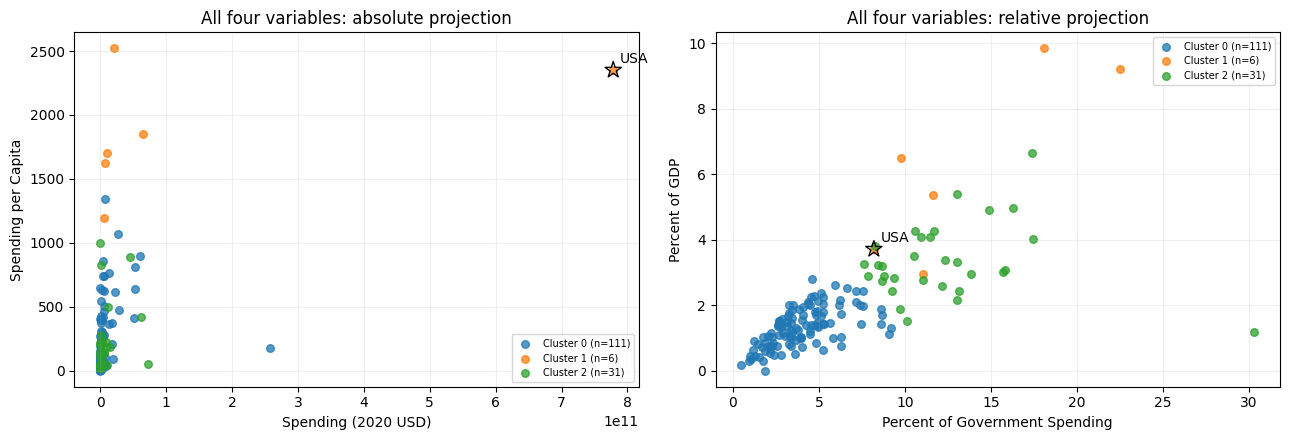

**United States: exact record and cluster assignments**

,Country,Spending (2020 USD),Spending per Capita,Percent of Government Spending,Percent of GDP,cluster_Absolute_Spending,cluster_Relative_Spending,cluster_All_Variables
144,United States of America,7.783972e+11,2351.631858,8.197624,3.717885,2,0,1


**Q2.2. Absolute spending and spending per person.** The fitted clusters contain **126, 21 and 1 countries**. The U.S. is the singleton: approximately **USD 778.4 billion** total and **USD 2351.63 per person**. The 21-country cluster has mean spending per person around **USD 1046**, compared with **USD 122** in the large cluster. Examples in the higher-per-person group include Australia, Israel, Kuwait, Norway and Singapore. China and India remain in the large group despite large total budgets, showing that the partition also reflects per-person spending. It is not a simple ranking of total military budgets. A singleton has undefined sample standard deviation in the describe table; that NaN is expected and is not a missing source value.

**Q2.3. Relative spending.** The clusters have **99, 39 and 10 countries** (ordered here by increasing mean government-budget share). Their mean government shares are about **3.58%, 9.87% and 17.13%**, and mean GDP shares are about **1.27%, 2.74% and 5.81%**. The U.S. joins the middle profile (39 countries), not a singleton. The high-share group includes Algeria, Armenia, Azerbaijan, Belarus, Israel, Jordan, Kuwait, Oman, Pakistan and Saudi Arabia. Thus the clusters reflect military budget/economic burden rather than spending scale, and span several regions.

**Q2.4. All four variables.** The fitted groups contain **111, 31 and 6 countries**. The six-country cluster consists of **Israel, Kuwait, Oman, Saudi Arabia, Singapore and the United States of America**. Its mean spending per person is about **USD 1875**, mean government share **13.54%**, and mean GDP share **6.26%**. The 31-country group has lower mean spending per person (about **USD 213**) but relatively high mean budget/GDP shares (about **12.30% / 3.35%**). The 111-country group has lower mean relative shares (**4.04% / 1.34%**). The U.S. therefore joins five peers instead of remaining alone. The two plots are projections of a four-dimensional fit, so overlap in either plot does not contradict cluster membership.

...

**Sensitivity to choosing k=2,3,4**

,Model,k,cluster sizes,USA cluster size,silhouette
0,Absolute_Spending,2,"[17, 131]",17,0.759211
1,Absolute_Spending,3,"[1, 21, 126]",1,0.742993
2,Absolute_Spending,4,"[1, 6, 30, 111]",1,0.701358
3,Relative_Spending,2,"[35, 113]",35,0.615869
4,Relative_Spending,3,"[10, 39, 99]",39,0.539431
5,Relative_Spending,4,"[3, 22, 40, 83]",40,0.446014
6,All_Variables,2,"[19, 129]",19,0.600902
7,All_Variables,3,"[6, 31, 111]",6,0.480058
8,All_Variables,4,"[6, 26, 30, 86]",6,0.407304


**Q2.5. Usefulness and limitations.** K-means distinguishes total scale, spending per person and relative budget burden, and shows how the U.S. changes peers with the feature set. These are useful descriptive profiles, not measures of military capability or evidence of causal or geopolitical relationships. Min-max scaling gives every feature the same range but does not remove skew or outlier influence; the U.S. compresses most total-spending values near zero. Related variables may also receive overlapping weight. The seed and k checks above distinguish numerical repeatability from substantive certainty: a stable fit can still depend on k and preprocessing. Log-spending and alternative scalings could be examined as additional sensitivity analyses; they were not substituted for the required min-max analysis. Conclusions apply to the 148 complete countries in 2020.

**Method references:** [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), [MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html), [clustering evaluation](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation).

Q2 verification passed: 148 unique countries; finite data; valid units and scaling; all three analyses completed.


In [27]:
# PHASE 2 - Q2. This cell imports everything it needs and reloads the CSV.
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display, Markdown

P2_SEED, P2_N_INIT = 100, 50
p2_features = ['Spending (2020 USD)', 'Spending per Capita',
               'Percent of Government Spending', 'Percent of GDP']
p2_specs = {'Absolute_Spending': p2_features[:2],
            'Relative_Spending': p2_features[2:],
            'All_Variables': p2_features}

# Q2.1: Explicit loading, 2020 filtering, missing-value removal and unit checks.
p2_paths = [Path('data/SIPRI Military Expenditure Database.csv'),
            Path('SIPRI Military Expenditure Database.csv'),
            Path('/content/SIPRI Military Expenditure Database.csv')]
p2_filepath = next((p for p in p2_paths if p.is_file()), None)
if p2_filepath is None:
    raise FileNotFoundError('Upload SIPRI Military Expenditure Database.csv to Colab or place it in ./data.')
p2_raw = pd.read_csv(p2_filepath)
p2_raw.columns = p2_raw.columns.str.strip()
p2_required = ['Year', 'Country'] + p2_features
missing_columns = set(p2_required) - set(p2_raw.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')
p2_work = p2_raw.drop(columns=['index'], errors='ignore').copy()
p2_work['Year'] = pd.to_numeric(p2_work['Year'], errors='raise')
p2_year = p2_work.loc[p2_work['Year'].eq(2020)].copy()
p2_missing_before = p2_year.isna().sum()
for feature in p2_features:
    p2_year[feature] = pd.to_numeric(p2_year[feature], errors='raise')
p2_year['Country'] = p2_year['Country'].str.strip().replace('', np.nan)
p2_2020_source = p2_year.dropna().reset_index(drop=True)
assert len(p2_2020_source) == 148, 'The provided version should contain 148 complete countries; investigate a different count.'
assert p2_2020_source['Country'].nunique() == 148
assert np.isfinite(p2_2020_source[p2_features].to_numpy()).all()
assert (p2_2020_source[p2_features] >= 0).all().all()
assert p2_2020_source[p2_features[2:]].le(1).all().all()

# The provided file stores spending in USD millions and shares as fractions.
# Convert units for accurate labels/tables. Each is a positive linear change,
# so min-max normalized values and fitted distances are unaffected.
p2_2020 = p2_2020_source.copy()
p2_2020['Spending (2020 USD)'] *= 1_000_000
p2_2020[p2_features[2:]] *= 100
assert np.allclose(MinMaxScaler().fit_transform(p2_2020_source[p2_features]),
                   MinMaxScaler().fit_transform(p2_2020[p2_features]))
p2_us_mask = p2_2020['Country'].str.casefold().isin(['united states', 'united states of america'])
assert p2_us_mask.sum() == 1
p2_us_index = p2_2020.index[p2_us_mask][0]

display(Markdown('**Q2.1. Cleaning and units**'))
print(f'Loaded: {p2_filepath}; source rows: {len(p2_raw)}; 2020 rows: {len(p2_year)}; dropped: {len(p2_year)-len(p2_2020)}; retained: {len(p2_2020)} countries.')
display(p2_missing_before.rename('Missing in 2020 before removal').to_frame())
display(p2_2020.loc[p2_us_mask, ['Country'] + p2_features])
display(Markdown(
    'Further preparation is required: exclude the exported **index** column and '
    'the constant **Year** from clustering, validate numeric types and country '
    'uniqueness, correct units, then scale the selected features. In this file, '
    'the U.S. spending entry 778397.2 represents **millions of USD**, giving '
    '**USD 778.3972 billion**; its GDP entry 0.037179 represents about **3.718%**, '
    'not 0.037179%. These unit interpretations are consistent with '
    '[SIPRI\'s 2020 report](https://www.sipri.org/media/press-release/2021/world-military-spending-rises-almost-2-trillion-2020). '
    'The unit check is an inference from the supplied values and that report. '
    'The retained rows are finite, nonnegative and unique by country. No '
    'additional numeric parsing is needed for this particular CSV. Removing '
    '25 incomplete countries may introduce selection bias. Extreme observations '
    'are retained as substantive data rather than treated as errors.'
))

def p2_fit_candidates(data, features):
    scaler = MinMaxScaler()
    X = scaler.fit_transform(data[features])
    assert np.isfinite(X).all() and X.min() >= -1e-10 and X.max() <= 1 + 1e-10
    grid = np.arange(1, 9)
    models = {int(k): KMeans(n_clusters=int(k), random_state=P2_SEED,
                             n_init=P2_N_INIT).fit(X) for k in grid}
    inertia = np.array([models[int(k)].inertia_ for k in grid])
    assert np.all(np.diff(inertia) <= 1e-8)
    # Transparent elbow heuristic: normalize both axes to [0,1] and find
    # the curve point farthest below the chord joining the two endpoints.
    # The candidate range matters; this is not a statistically unique optimum.
    scaled_k = (grid - grid[0]) / (grid[-1] - grid[0])
    scaled_inertia = (inertia - inertia[-1]) / (inertia[0] - inertia[-1])
    gap = (1 - scaled_k) - scaled_inertia
    chosen_k = int(grid[1:-1][np.argmax(gap[1:-1])])
    table = pd.DataFrame({
        'k': grid, 'inertia': inertia,
        'drop_from_previous_pct': np.r_[np.nan, 100 * (1 - inertia[1:] / inertia[:-1])],
        'silhouette': [np.nan] + [silhouette_score(X, models[k].labels_) for k in range(2, 9)],
        'elbow_chord_gap': gap,
    }).set_index('k')
    return {'features': features, 'X': X, 'scaler': scaler, 'models': models,
            'k': chosen_k, 'diagnostics': table}

p2_results = {name: p2_fit_candidates(p2_2020, features)
              for name, features in p2_specs.items()}
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, result) in zip(axes, p2_results.items()):
    diag, k = result['diagnostics'], result['k']
    ax.plot(diag.index, diag.inertia, 'o-')
    ax.axvline(k, color='tab:red', linestyle='--', label=f'Chord heuristic: k={k}')
    ax.set(title=name.replace('_', ' '), xlabel='k', ylabel='Inertia in normalized feature space')
    ax.set_xticks(diag.index)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()
for name, result in p2_results.items():
    display(Markdown(f'**{name}: candidate-k evidence**'))
    display(result['diagnostics'].round(4))
display(Markdown(
    'For this CSV, the chord heuristic selects **k = 3 for all three feature sets**, '
    'but the evidence is not equally decisive. For absolute spending, inertia is '
    '2.4353, 1.3218 and 0.6294 at k=2,3,4, so four clusters remain plausible. '
    'For relative spending, the chord gaps at k=2 and k=3 are almost tied '
    '(0.4846 and 0.4866), making two clusters a reasonable alternative. For all '
    'four variables, the drop falls from about 32.6% (2 to 3) to 19.0% (3 to 4). '
    'Silhouette favors k=2 in all three cases. I retain k=3 as an interpretable '
    'elbow-based working choice that distinguishes three profiles, and report '
    'the competing evidence rather than call it a proven optimum. Inertias '
    'from different feature sets are not directly comparable quality scores.'
))

def p2_scatter(ax, data, label_col, x, y, model_name):
    for cluster, group in data.groupby(label_col):
        ax.scatter(group[x], group[y], label=f'Cluster {cluster} (n={len(group)})',
                   color=plt.get_cmap('tab10')(int(cluster)), alpha=0.75, s=30)
    us = data.loc[p2_us_mask].iloc[0]
    ax.scatter(us[x], us[y], marker='*', s=150, facecolors='none', edgecolors='black')
    ax.annotate('USA', (us[x], us[y]), xytext=(5, 5), textcoords='offset points')
    ax.set(xlabel=x, ylabel=y, title=model_name)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.2)

# Q2.2-4: Fit in normalized space; interpret tables/plots in corrected units.
p2_membership = p2_2020.copy()
for name, result in p2_results.items():
    k = result['k']
    result['model'] = result['models'][k]
    label_col = f'cluster_{name}'
    p2_membership[label_col] = result['model'].labels_
    assert p2_membership[label_col].value_counts().sum() == len(p2_2020)
    result['label_col'] = label_col
    display(Markdown(f'**{name}: selected k={k}; cluster sizes and mean profiles**'))
    display(p2_membership.groupby(label_col).size().rename('Countries').to_frame())
    display(p2_membership.groupby(label_col)[p2_features].mean())
    # Required full groupby(...).describe(), with feature rows to avoid truncation.
    describe = p2_membership.groupby(label_col)[result['features']].describe()
    display(Markdown('**Conditional describe table** (corrected USD, USD per person and percentage-point units)'))
    display(describe.T)
    display(Markdown('**Country membership by cluster**'))
    with pd.option_context('display.max_colwidth', None):
        display(p2_membership.groupby(label_col)['Country'].agg(', '.join).to_frame())
    if name == 'All_Variables':
        fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
        p2_scatter(axes[0], p2_membership, label_col, *p2_features[:2], 'All four variables: absolute projection')
        p2_scatter(axes[1], p2_membership, label_col, *p2_features[2:], 'All four variables: relative projection')
    else:
        fig, ax = plt.subplots(figsize=(8, 4.5))
        p2_scatter(ax, p2_membership, label_col, *result['features'], name.replace('_', ' '))
    plt.tight_layout()
    plt.show()

p2_label_cols = [result['label_col'] for result in p2_results.values()]
display(Markdown('**United States: exact record and cluster assignments**'))
display(p2_membership.loc[p2_us_mask, ['Country'] + p2_features + p2_label_cols])
display(Markdown(
    '**Q2.2. Absolute spending and spending per person.** The fitted clusters '
    'contain **126, 21 and 1 countries**. The U.S. is the singleton: approximately '
    '**USD 778.4 billion** total and **USD 2351.63 per person**. The 21-country cluster '
    'has mean spending per person around **USD 1046**, compared with **USD 122** in '
    'the large cluster. Examples in the higher-per-person group include Australia, '
    'Israel, Kuwait, Norway and Singapore. China and India remain in the large '
    'group despite large total budgets, showing that the partition also reflects '
    'per-person spending. It is not a simple ranking of total military budgets. '
    'A singleton has undefined sample standard deviation in the describe table; '
    'that NaN is expected and is not a missing source value.'
))
display(Markdown(
    '**Q2.3. Relative spending.** The clusters have **99, 39 and 10 countries** '
    '(ordered here by increasing mean government-budget share). Their mean '
    'government shares are about **3.58%, 9.87% and 17.13%**, and mean GDP shares '
    'are about **1.27%, 2.74% and 5.81%**. The U.S. joins the middle profile '
    '(39 countries), not a singleton. The high-share group includes Algeria, '
    'Armenia, Azerbaijan, Belarus, Israel, Jordan, Kuwait, Oman, Pakistan and '
    'Saudi Arabia. Thus the clusters reflect military budget/economic burden '
    'rather than spending scale, and span several regions.'
))
display(Markdown(
    '**Q2.4. All four variables.** The fitted groups contain **111, 31 and 6 '
    'countries**. The six-country cluster consists of **Israel, Kuwait, Oman, '
    'Saudi Arabia, Singapore and the United States of America**. Its mean '
    'spending per person is about **USD 1875**, mean government share **13.54%**, '
    'and mean GDP share **6.26%**. The 31-country group has lower mean spending '
    'per person (about **USD 213**) but relatively high mean budget/GDP shares '
    '(about **12.30% / 3.35%**). The 111-country group has lower mean relative '
    'shares (**4.04% / 1.34%**). The U.S. therefore joins five peers instead of '
    'remaining alone. The two plots are projections of a four-dimensional fit, '
    'so overlap in either plot does not contradict cluster membership.'
))

# Compare partitions without mistaking arbitrary numeric labels for meanings.
display(Markdown('**Cross-model membership comparisons**'))
p2_comparison = []
for a, b in combinations(p2_results, 2):
    ca, cb = p2_results[a]['label_col'], p2_results[b]['label_col']
    p2_comparison.append({'Model A': a, 'Model B': b,
                         'Adjusted Rand index': adjusted_rand_score(p2_membership[ca], p2_membership[cb])})
    display(pd.crosstab(p2_membership[ca], p2_membership[cb]))
display(pd.DataFrame(p2_comparison))

# Check sensitivity to k and to the random initialization.
p2_sensitivity = []
for name, result in p2_results.items():
    for k in [2, 3, 4]:
        labels = result['models'][k].labels_
        p2_sensitivity.append({'Model': name, 'k': k,
            'cluster sizes': sorted(np.bincount(labels).tolist()),
            'USA cluster size': int((labels == labels[p2_us_index]).sum()),
            'silhouette': silhouette_score(result['X'], labels)})
    reference = result['model'].labels_
    agreements = [adjusted_rand_score(reference, KMeans(n_clusters=result['k'],
                  random_state=seed, n_init=P2_N_INIT).fit_predict(result['X']))
                  for seed in [0, 1, 2, 3, 4]]
    print(f'{name}: minimum ARI against five alternative seeds = {min(agreements):.4f}')
display(Markdown('**Sensitivity to choosing k=2,3,4**'))
display(pd.DataFrame(p2_sensitivity))
display(Markdown(
    '**Q2.5. Usefulness and limitations.** K-means distinguishes total scale, '
    'spending per person and relative budget burden, and shows how the U.S. '
    'changes peers with the feature set. These are useful descriptive profiles, '
    'not measures of military capability or evidence of causal or geopolitical '
    'relationships. Min-max scaling gives every feature the same range but does '
    'not remove skew or outlier influence; the U.S. compresses most total-spending '
    'values near zero. Related variables may also receive overlapping weight. '
    'The seed and k checks above distinguish numerical repeatability from '
    'substantive certainty: a stable fit can still depend on k and preprocessing. '
    'Log-spending and alternative scalings could be examined as additional '
    'sensitivity analyses; they were not substituted for the required min-max '
    'analysis. Conclusions apply to the 148 complete countries in 2020.'
))
display(Markdown(
    '**Method references:** '
    '[KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html), '
    '[MinMaxScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.MinMaxScaler.html), '
    '[clustering evaluation](https://scikit-learn.org/stable/modules/clustering.html#clustering-performance-evaluation).'
))
print('Q2 verification passed: 148 unique countries; finite data; valid units and scaling; all three analyses completed.')


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

The ai agent did a very extensive and complete rework of much of my code, it found more errors than I expected. The agents new code reloads the actual CSV and filters it to 148 complete countries for 2020. It also corrected some units, revised comments to be more detailed, and did stronger verification of the evidence. The AI's original solution had a string-literal error, which was corrected. Some draft numerical prose was corrected against the computed tables, and currency notation was adjusted to avoid unintended math rendering. I was concerned at first that the phase 2 cells didn't run properly at first but I realized the issue was small and fixed it. Overall I was impressed with the work it did, my one remaining concern would be that its solution is very long and it was hard to verify exactly everything it changed. I verified its solution by running all cells and making sure its answers were aligned with what I expected.